In [44]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

IMPORT DATA

In [45]:
df_test_raw = pd.read_csv('test.csv')

df_test_raw.head(10)

,id,tweet
0,31963,#studiolife #aislife #requires #passion #dedication #willpower to find #newmaterialsâ¦
1,31964,@user #white #supremacists want everyone to see the new â #birdsâ #movie â and hereâs why
2,31965,safe ways to heal your #acne!! #altwaystoheal #healthy #healing!!
3,31966,"is the hp and the cursed child book up for reservations already? if yes, where? if no, when? ððð #harrypotter #pottermore #favorite"
4,31967,"3rd #bihday to my amazing, hilarious #nephew eli ahmir! uncle dave loves you and missesâ¦"
5,31968,choose to be :) #momtips
6,31969,something inside me dies ð¦ð¿â¨ eyes ness #smokeyeyes #tired #lonely #sof #grungeâ¦
7,31970,#finished#tattoo#inked#ink#loveitâ¤ï¸ #â¤ï¸â¤ï¸â¤ï¸â¤ï¸ #thanks#aleeee !!!
8,31971,@user @user @user i will never understand why my dad left me when i was so young.... :/ #deep #inthefeels
9,31972,#delicious #food #lovelife #capetown mannaepicure #resturantâ¦


In [46]:
print("Jumlah missing values:", df_test_raw['tweet'].isnull().sum())
print("Apakah ada missing values:", df_test_raw['tweet'].isnull().any())

Jumlah missing values: 0
Apakah ada missing values: False


In [47]:
df_train_raw = pd.read_csv('train.csv')

df_train_raw.head(10)

,id,label,tweet
0,1,0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0,factsguide: society now #motivation
5,6,0,[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo
6,7,0,@user camping tomorrow @user @user @user @user @user @user @user dannyâ¦
7,8,0,the next school year is the year for exams.ð¯ can't think about that ð­ #school #exams #hate #imagine #actorslife #revolutionschool #girl
8,9,0,we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers â¦
9,10,0,@user @user welcome here ! i'm it's so #gr8 !


In [48]:
print("Jumlah missing values:", df_train_raw['tweet'].isnull().sum())
print("Apakah ada missing values:", df_train_raw['tweet'].isnull().any())

Jumlah missing values: 0
Apakah ada missing values: False


In [49]:
!pip install nltk -q


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
import nltk
from IPython.display import display

nltk.download('stopwords', quiet=True)

df_train = df_train_raw.copy()
df_train['tweet'] = df_train['tweet'].fillna('').astype(str)

pd.set_option('display.max_colwidth', None)

print("Jumlah data:", len(df_train))
print("Kolom dataset:", df_train.columns.tolist())

display(df_train[['label', 'tweet']].head(5))

Jumlah data: 31962
Kolom dataset: ['id', 'label', 'tweet']


,label,tweet
0,0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,0,bihday your majesty
3,0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,0,factsguide: society now #motivation


In [51]:
df_test = df_test_raw.copy()

df_test['tweet'] = df_test['tweet'].fillna('').astype(str)

pd.set_option('display.max_colwidth', None)

print("Jumlah data:", len(df_test))
print("Kolom dataset:", df_test.columns.tolist())

display(df_test[['tweet']].head(5))

Jumlah data: 17197
Kolom dataset: ['id', 'tweet']


,tweet
0,#studiolife #aislife #requires #passion #dedication #willpower to find #newmaterialsâ¦
1,@user #white #supremacists want everyone to see the new â #birdsâ #movie â and hereâs why
2,safe ways to heal your #acne!! #altwaystoheal #healthy #healing!!
3,"is the hp and the cursed child book up for reservations already? if yes, where? if no, when? ððð #harrypotter #pottermore #favorite"
4,"3rd #bihday to my amazing, hilarious #nephew eli ahmir! uncle dave loves you and missesâ¦"


In [52]:
import re
import html

def clean_tweet(text):
    text = str(text)

    # 1. Decode HTML entities, misalnya &amp; menjadi &
    text = html.unescape(text)

    # 2. Menghapus URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # 3. Menghapus mention seperti @user
    text = re.sub(r'@\w+', ' ', text)

    # 4. Menghapus hashtag beserta katanya
    text = re.sub(r'#\w+', ' ', text)

    # 5. Menghapus pola karakter rusak akibat encoding
    text = re.sub(r'ð\S*|â\S*|ï\S*|�+', ' ', text)

    # 6. Menghapus karakter non-ASCII yang tersisa
    text = text.encode('ascii', errors='ignore').decode('ascii')

    # 7. Menghapus angka yang berdiri sendiri
    text = re.sub(r'\b\d+\b', ' ', text)

    # 8. Menghapus tanda baca dan simbol
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    # 10. Merapikan spasi
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [53]:
df_train_clean = df_train.copy()
df_test_clean = df_test.copy()

df_train_clean['tweet_clean'] = df_train_clean['tweet'].apply(clean_tweet)
df_test_clean['tweet_clean'] = df_test_clean['tweet'].apply(clean_tweet)

In [54]:
print("Jumlah data train:", len(df_train_clean))
print("Jumlah data test :", len(df_test_clean))

print("\nHasil cleaning TRAIN:")
display(
    df_train_clean[['tweet', 'tweet_clean']].head(10).style
    .set_properties(
        subset=['tweet', 'tweet_clean'],
        **{'text-align': 'left', 'white-space': 'pre-wrap'}
    )
)

print("\nHasil cleaning TEST:")
display(
    df_test_clean[['tweet', 'tweet_clean']].head(10).style
    .set_properties(
        subset=['tweet', 'tweet_clean'],
        **{'text-align': 'left', 'white-space': 'pre-wrap'}
    )
)

Jumlah data train: 31962
Jumlah data test : 17197

Hasil cleaning TRAIN:


,tweet,tweet_clean
0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction
1,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks for credit i can t use cause they don t offer wheelchair vans in pdx
2,bihday your majesty,bihday your majesty
3,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,i love u take with u all the time in ur
4,factsguide: society now #motivation,factsguide society now
5,[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo,huge fan fare and big talking before they leave chaos and pay disputes when they get there
6,@user camping tomorrow @user @user @user @user @user @user @user dannyâ¦,camping tomorrow danny
7,the next school year is the year for exams.ð¯ can't think about that ð­ #school #exams #hate #imagine #actorslife #revolutionschool #girl,the next school year is the year for exams can t think about that
8,we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers â¦,we won love the land
9,@user @user welcome here ! i'm it's so #gr8 !,welcome here i m it s so



Hasil cleaning TEST:


,tweet,tweet_clean
0,#studiolife #aislife #requires #passion #dedication #willpower to find #newmaterialsâ¦,to find
1,@user #white #supremacists want everyone to see the new â #birdsâ #movie â and hereâs why,want everyone to see the new and here why
2,safe ways to heal your #acne!! #altwaystoheal #healthy #healing!!,safe ways to heal your
3,"is the hp and the cursed child book up for reservations already? if yes, where? if no, when? ððð #harrypotter #pottermore #favorite",is the hp and the cursed child book up for reservations already if yes where if no when
4,"3rd #bihday to my amazing, hilarious #nephew eli ahmir! uncle dave loves you and missesâ¦",3rd to my amazing hilarious eli ahmir uncle dave loves you and misses
5,choose to be :) #momtips,choose to be
6,something inside me dies ð¦ð¿â¨ eyes ness #smokeyeyes #tired #lonely #sof #grungeâ¦,something inside me dies eyes ness
7,#finished#tattoo#inked#ink#loveitâ¤ï¸ #â¤ï¸â¤ï¸â¤ï¸â¤ï¸ #thanks#aleeee !!!,
8,@user @user @user i will never understand why my dad left me when i was so young.... :/ #deep #inthefeels,i will never understand why my dad left me when i was so young
9,#delicious #food #lovelife #capetown mannaepicure #resturantâ¦,mannaepicure


In [55]:
df_train_casefold = df_train_clean.copy()
df_test_casefold = df_test_clean.copy()

df_train_casefold['tweet_casefold'] = (
    df_train_casefold['tweet_clean'].str.lower()
)

df_test_casefold['tweet_casefold'] = (
    df_test_casefold['tweet_clean'].str.lower()
)

In [56]:
print("Hasil Case Folding - TRAIN")
display(
    df_train_casefold[
        ['tweet_clean', 'tweet_casefold']
    ].head(10).style
    .set_properties(
        subset=['tweet_clean', 'tweet_casefold'],
        **{'text-align': 'left', 'white-space': 'pre-wrap'}
    )
)

print("Hasil Case Folding - TEST")
display(
    df_test_casefold[
        ['tweet_clean', 'tweet_casefold']
    ].head(10).style
    .set_properties(
        subset=['tweet_clean', 'tweet_casefold'],
        **{'text-align': 'left', 'white-space': 'pre-wrap'}
    )
)

Hasil Case Folding - TRAIN


,tweet_clean,tweet_casefold
0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction
1,thanks for credit i can t use cause they don t offer wheelchair vans in pdx,thanks for credit i can t use cause they don t offer wheelchair vans in pdx
2,bihday your majesty,bihday your majesty
3,i love u take with u all the time in ur,i love u take with u all the time in ur
4,factsguide society now,factsguide society now
5,huge fan fare and big talking before they leave chaos and pay disputes when they get there,huge fan fare and big talking before they leave chaos and pay disputes when they get there
6,camping tomorrow danny,camping tomorrow danny
7,the next school year is the year for exams can t think about that,the next school year is the year for exams can t think about that
8,we won love the land,we won love the land
9,welcome here i m it s so,welcome here i m it s so


Hasil Case Folding - TEST


,tweet_clean,tweet_casefold
0,to find,to find
1,want everyone to see the new and here why,want everyone to see the new and here why
2,safe ways to heal your,safe ways to heal your
3,is the hp and the cursed child book up for reservations already if yes where if no when,is the hp and the cursed child book up for reservations already if yes where if no when
4,3rd to my amazing hilarious eli ahmir uncle dave loves you and misses,3rd to my amazing hilarious eli ahmir uncle dave loves you and misses
5,choose to be,choose to be
6,something inside me dies eyes ness,something inside me dies eyes ness
7,,
8,i will never understand why my dad left me when i was so young,i will never understand why my dad left me when i was so young
9,mannaepicure,mannaepicure


In [57]:
from nltk.tokenize import TweetTokenizer
from IPython.display import display

df_train_tokenized = df_train_casefold.copy()
df_test_tokenized = df_test_casefold.copy()

tokenizer = TweetTokenizer()

# Tokenization untuk TRAIN
df_train_tokenized['tokens'] = (
    df_train_tokenized['tweet_casefold'].apply(tokenizer.tokenize)
)

# Tokenization untuk TEST
df_test_tokenized['tokens'] = (
    df_test_tokenized['tweet_casefold'].apply(tokenizer.tokenize)
)

In [58]:
print("Hasil Tokenization - TRAIN")
display(
    df_train_tokenized[['tweet_casefold', 'tokens']].head(10)
)

print("Hasil Tokenization - TEST")
display(
    df_test_tokenized[['tweet_casefold', 'tokens']].head(10)
)

Hasil Tokenization - TRAIN


,tweet_casefold,tokens
0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction,"[when, a, father, is, dysfunctional, and, is, so, selfish, he, drags, his, kids, into, his, dysfunction]"
1,thanks for credit i can t use cause they don t offer wheelchair vans in pdx,"[thanks, for, credit, i, can, t, use, cause, they, don, t, offer, wheelchair, vans, in, pdx]"
2,bihday your majesty,"[bihday, your, majesty]"
3,i love u take with u all the time in ur,"[i, love, u, take, with, u, all, the, time, in, ur]"
4,factsguide society now,"[factsguide, society, now]"
5,huge fan fare and big talking before they leave chaos and pay disputes when they get there,"[huge, fan, fare, and, big, talking, before, they, leave, chaos, and, pay, disputes, when, they, get, there]"
6,camping tomorrow danny,"[camping, tomorrow, danny]"
7,the next school year is the year for exams can t think about that,"[the, next, school, year, is, the, year, for, exams, can, t, think, about, that]"
8,we won love the land,"[we, won, love, the, land]"
9,welcome here i m it s so,"[welcome, here, i, m, it, s, so]"


Hasil Tokenization - TEST


,tweet_casefold,tokens
0,to find,"[to, find]"
1,want everyone to see the new and here why,"[want, everyone, to, see, the, new, and, here, why]"
2,safe ways to heal your,"[safe, ways, to, heal, your]"
3,is the hp and the cursed child book up for reservations already if yes where if no when,"[is, the, hp, and, the, cursed, child, book, up, for, reservations, already, if, yes, where, if, no, when]"
4,3rd to my amazing hilarious eli ahmir uncle dave loves you and misses,"[3rd, to, my, amazing, hilarious, eli, ahmir, uncle, dave, loves, you, and, misses]"
5,choose to be,"[choose, to, be]"
6,something inside me dies eyes ness,"[something, inside, me, dies, eyes, ness]"
7,,[]
8,i will never understand why my dad left me when i was so young,"[i, will, never, understand, why, my, dad, left, me, when, i, was, so, young]"
9,mannaepicure,[mannaepicure]


In [59]:
import nltk
from nltk.corpus import stopwords
from IPython.display import display

df_train_stopwords = df_train_tokenized.copy()
df_test_stopwords = df_test_tokenized.copy()

nltk.download('stopwords', quiet=True)

# Stopwords bahasa Inggris
stop_words = set(stopwords.words('english'))

# Kata negasi yang dipertahankan untuk analisis sentimen
preserve_words = {'no', 'nor', 'not', 'never'}

stop_words = stop_words - preserve_words

# Stopword Removal - TRAIN
df_train_stopwords['stopwords'] = (
    df_train_stopwords['tokens'].apply(
        lambda tokens: [
            word for word in tokens
            if word.lower() not in stop_words
        ]
    )
)

# Stopword Removal - TEST
df_test_stopwords['stopwords'] = (
    df_test_stopwords['tokens'].apply(
        lambda tokens: [
            word for word in tokens
            if word.lower() not in stop_words
        ]
    )
)

# Menampilkan hasil
print("Hasil Stopword Removal - TRAIN")
display(
    df_train_stopwords[['tokens', 'stopwords']].head(30)
)

print("Hasil Stopword Removal - TEST")
display(
    df_test_stopwords[['tokens', 'stopwords']].head(30)
)

Hasil Stopword Removal - TRAIN


,tokens,stopwords
0,"[when, a, father, is, dysfunctional, and, is, so, selfish, he, drags, his, kids, into, his, dysfunction]","[father, dysfunctional, selfish, drags, kids, dysfunction]"
1,"[thanks, for, credit, i, can, t, use, cause, they, don, t, offer, wheelchair, vans, in, pdx]","[thanks, credit, use, cause, offer, wheelchair, vans, pdx]"
2,"[bihday, your, majesty]","[bihday, majesty]"
3,"[i, love, u, take, with, u, all, the, time, in, ur]","[love, u, take, u, time, ur]"
4,"[factsguide, society, now]","[factsguide, society]"
5,"[huge, fan, fare, and, big, talking, before, they, leave, chaos, and, pay, disputes, when, they, get, there]","[huge, fan, fare, big, talking, leave, chaos, pay, disputes, get]"
6,"[camping, tomorrow, danny]","[camping, tomorrow, danny]"
7,"[the, next, school, year, is, the, year, for, exams, can, t, think, about, that]","[next, school, year, year, exams, think]"
8,"[we, won, love, the, land]","[love, land]"
9,"[welcome, here, i, m, it, s, so]",[welcome]


Hasil Stopword Removal - TEST


,tokens,stopwords
0,"[to, find]",[find]
1,"[want, everyone, to, see, the, new, and, here, why]","[want, everyone, see, new]"
2,"[safe, ways, to, heal, your]","[safe, ways, heal]"
3,"[is, the, hp, and, the, cursed, child, book, up, for, reservations, already, if, yes, where, if, no, when]","[hp, cursed, child, book, reservations, already, yes, no]"
4,"[3rd, to, my, amazing, hilarious, eli, ahmir, uncle, dave, loves, you, and, misses]","[3rd, amazing, hilarious, eli, ahmir, uncle, dave, loves, misses]"
5,"[choose, to, be]",[choose]
6,"[something, inside, me, dies, eyes, ness]","[something, inside, dies, eyes, ness]"
7,[],[]
8,"[i, will, never, understand, why, my, dad, left, me, when, i, was, so, young]","[never, understand, dad, left, young]"
9,[mannaepicure],[mannaepicure]


In [60]:
# from nltk.stem import PorterStemmer
# from IPython.display import display

# # Copy DataFrame hasil stopword removal
# df_train_stemmed = df_train_stopwords.copy()
# df_test_stemmed = df_test_stopwords.copy()

# # Inisialisasi stemmer
# stemmer = PorterStemmer()

# # Stemming - TRAIN
# df_train_stemmed['tokens_stemmed'] = (
#     df_train_stemmed['stopwords'].apply(
#         lambda tokens: [
#             stemmer.stem(word) for word in tokens
#         ]
#     )
# )

# # Stemming - TEST
# df_test_stemmed['tokens_stemmed'] = (
#     df_test_stemmed['stopwords'].apply(
#         lambda tokens: [
#             stemmer.stem(word) for word in tokens
#         ]
#     )
# )

# # Menampilkan hasil TRAIN
# print("Hasil Stemming - TRAIN")
# display(
#     df_train_stemmed[
#         ['stopwords', 'tokens_stemmed']
#     ].head(30)
# )

# # Menampilkan hasil TEST
# print("Hasil Stemming - TEST")
# display(
#     df_test_stemmed[
#         ['stopwords', 'tokens_stemmed']
#     ].head(30)
# )

In [61]:
# from nltk.stem import PorterStemmer
# from IPython.display import display

# df_train_stemmed = df_train_stopwords.copy()
# df_test_stemmed = df_test_stopwords.copy()

# stemmer = PorterStemmer()

# # Stemming - TRAIN
# df_train_stemmed['tokens_stemmed'] = (
#     df_train_stemmed['stopwords'].apply(
#         lambda tokens: [stemmer.stem(word) for word in tokens]
#     )
# )

# # Stemming - TEST
# df_test_stemmed['tokens_stemmed'] = (
#     df_test_stemmed['stopwords'].apply(
#         lambda tokens: [stemmer.stem(word) for word in tokens]
#     )
# )

# print("Hasil Stemming - TRAIN")
# display(
#     df_train_stemmed[
#         ['stopwords', 'tokens_stemmed']
#     ].head(10)
# )

# print("Hasil Stemming - TEST")
# display(
#     df_test_stemmed[
#         ['stopwords', 'tokens_stemmed']
#     ].head(10)
# )

In [62]:
from IPython.display import display

# Membuat DataFrame baru
df_train_clean = df_train_stopwords.copy()
df_test_clean = df_test_raw.copy()

# Menyimpan hasil akhir preprocessing ke kolom 'tweet'
df_train_clean['tweet'] = df_train_clean['stopwords'].apply(
    lambda tokens: ' '.join(tokens)
)

df_test_clean['tweet'] = df_test_clean['stopwords'].apply(
    lambda tokens: ' '.join(tokens)
)

# Menampilkan hasil TRAIN (tweet dan label)
print("Final Preprocessed Data - TRAIN")
display(
    df_train_clean[['tweet', 'label']].head(10)
)

# Menampilkan hasil TEST (tweet saja, karena tidak ada label)
print("Final Preprocessed Data - TEST")
display(
    df_test_clean[['tweet']].head(10)
)

# Menampilkan ukuran dataset
print("Ukuran Data:")
print(f"Train: {df_train_clean.shape[0]} baris")
print(f"Test : {df_test_clean.shape[0]} baris")

KeyError: 'stopwords'

In [ ]:
from sklearn.model_selection import train_test_split

X = df_train_clean['tweet']
y = df_train_clean['label']

X_test = df_test_clean['tweet']

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# ==========================================
# 1. Tokenisasi teks
# ==========================================
vocab_size = 10000
max_length = 50

tokenizer_rnn = Tokenizer(
    num_words=vocab_size,
    oov_token='<OOV>'
)

# Tokenizer belajar dari data training saja
tokenizer_rnn.fit_on_texts(X_train)

X_train_seq = tokenizer_rnn.texts_to_sequences(X_train)
X_val_seq = tokenizer_rnn.texts_to_sequences(X_val)
X_test_seq = tokenizer_rnn.texts_to_sequences(X_test)

# ==========================================
# 2. Padding
# ==========================================
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

actual_vocab_size = min(
    vocab_size,
    len(tokenizer_rnn.word_index) + 1
)

# Label sudah berupa angka 0 dan 1
y_train_model = y_train.to_numpy(dtype='int32')
y_val_model = y_val.to_numpy(dtype='int32')

# ==========================================
# 3. Create model SimpleRNN
# ==========================================
tf.keras.utils.set_random_seed(42)

model_rnn = Sequential([
    Embedding(
        input_dim=actual_vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    SimpleRNN(
        64,
        activation='tanh'
    ),
    Dropout(0.3),
    Dense(
        1,
        activation='sigmoid'
    )
])

# ==========================================
# 4. Compile model
# ==========================================
model_rnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Arsitektur Model SimpleRNN:")
model_rnn.summary()

# ==========================================
# 5. Training model
# ==========================================
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_rnn = model_rnn.fit(
    X_train_pad,
    y_train_model,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_pad, y_val_model),
    callbacks=[early_stopping],
    verbose=1
)


Arsitektur Model SimpleRNN:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9397 - loss: 0.2184 - val_accuracy: 0.9504 - val_loss: 0.1649
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9742 - loss: 0.0874 - val_accuracy: 0.9324 - val_loss: 0.2142
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9889 - loss: 0.0429 - val_accuracy: 0.9421 - val_loss: 0.2406
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9934 - loss: 0.0270 - val_accuracy: 0.9345 - val_loss: 0.2946
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9947 - loss: 0.0224 - val_accuracy: 0.9412 - val_loss: 0.2954
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9946 - loss: 0.0197 - val_accuracy: 0.9340 - val_loss: 0.3202
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9958 - loss: 0.0174 - val_accuracy: 0.9373 - val_loss: 0.3328
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9958 - loss: 0.0159 - val_accuracy: 0.

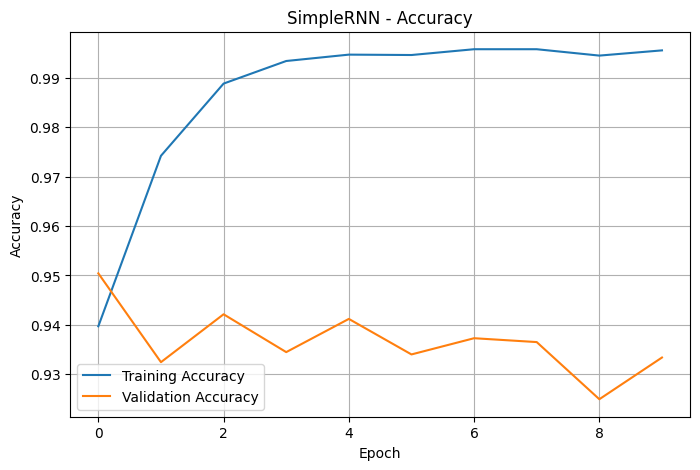

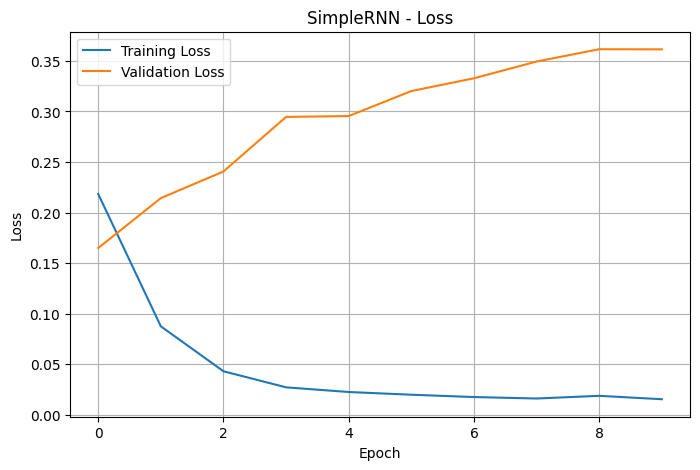

In [ ]:
import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history_rnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('SimpleRNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history_rnn.history['loss'], label='Training Loss')
plt.plot(history_rnn.history['val_loss'], label='Validation Loss')
plt.title('SimpleRNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Classification Report - Validation
              precision    recall  f1-score   support

Negative (0)       0.96      0.99      0.97      5945
Positive (1)       0.74      0.45      0.56       448

    accuracy                           0.95      6393
   macro avg       0.85      0.72      0.77      6393
weighted avg       0.94      0.95      0.94      6393



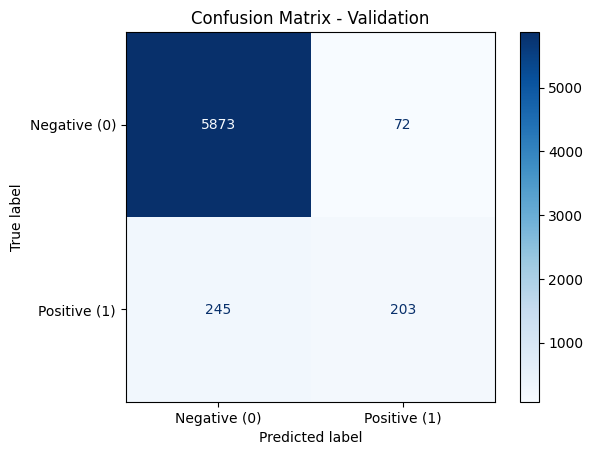

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Prediksi data validation
y_val_prob = model_rnn.predict(X_val_pad, verbose=0)
y_val_pred = (y_val_prob.ravel() >= 0.5).astype(int)

# Deskripsi label
target_names = ['Negative (0)', 'Positive (1)']

print("Classification Report - Validation")
print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1],
    target_names=target_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Validation')
plt.show()

In [ ]:
confident score

SyntaxError: invalid syntax (741679342.py, line 1)

In [ ]:
from IPython.display import display
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Ambil data test yang sudah preprocessing
X_test_text = df_test_clean['tweet'].fillna('').astype(str)

# Tokenisasi menggunakan tokenizer dari training
X_test_seq = tokenizer_rnn.texts_to_sequences(X_test_text)

# Padding dengan panjang yang sama seperti training
X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=50,
    padding='post',
    truncating='post'
)

# Prediksi
y_test_prob = model_rnn.predict(X_test_pad, verbose=0)
y_test_pred = (y_test_prob.ravel() >= 0.5).astype(int)

# Simpan hasil prediksi
df_test_prediction = df_test_clean[['tweet']].copy()
df_test_prediction['predicted_label'] = y_test_pred
df_test_prediction['predicted_sentiment'] = df_test_prediction['predicted_label'].map({
    0: 'Negative',
    1: 'Positive'
})

print("Hasil Prediksi pada Data Test")
display(df_test_prediction.head(100))

print("\nJumlah data test:", len(df_test_prediction))
print("\nDistribusi prediksi:")
display(df_test_prediction['predicted_sentiment'].value_counts())

Hasil Prediksi pada Data Test


,tweet,predicted_label,predicted_sentiment
0,find,0,Negative
1,want everyone see new,0,Negative
2,safe ways heal,0,Negative
3,hp cursed child book reservations already yes no,0,Negative
4,3rd amazing hilarious eli ahmir uncle dave loves misses,0,Negative
...,...,...,...
95,great see look forward welcoming digme,0,Negative
96,jackblair na,0,Negative
97,u take pour one big cup no drink delivered,0,Negative
98,happy father day dad hope u great day love u fathersday,0,Negative



Jumlah data test: 17197

Distribusi prediksi:


predicted_sentiment
Negative    16412
Positive      785
Name: count, dtype: int64